# Fig1 Correlation Matrix

**Figure 1** — Pearson Correlation Matrix of all engineered features.

Run this notebook to reproduce Figure 1 for the manuscript (3000×1800 px, 150 DPI).

> **Run cells in order: Cell 1 → Cell 2 → Cell 3**

In [1]:
# Install / upgrade required libraries
!pip install matplotlib numpy pandas scikit-learn -q



[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)

# ── Global constants (real project results) ──
DPI   = 150
W_IN  = 3000 / DPI   # 20 inches
H_IN  = 1800 / DPI   # 12 inches
BG    = '#F7F9FC'

CITIES        = ['Riyadh', 'Jeddah', 'Abha', 'Dammam', 'Qassim']
SEASONS       = ['Spring', 'Summer', 'Autumn', 'Winter']
MONTHS        = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
CITY_COLORS   = ['#1F4E79','#2E75B6','#C00000','#ED7D31','#70AD47']
SEASON_COLORS = {'Spring':'#70AD47','Summer':'#ED7D31','Autumn':'#C00000','Winter':'#1F4E79'}

BASELINE = {
    'Riyadh':  dict(rmse=51.68, mae=25.57, r2=0.9747, bias=-4.04,  paper=100.6),
    'Jeddah':  dict(rmse=49.49, mae=25.93, r2=0.9769, bias=-6.20,  paper=101.0),
    'Abha':    dict(rmse=67.70, mae=39.89, r2=0.9562, bias=-8.83,  paper=107.4),
    'Dammam':  dict(rmse=49.19, mae=25.45, r2=0.9758, bias=-3.50,  paper=92.4),
    'Qassim':  dict(rmse=47.28, mae=24.72, r2=0.9785, bias=-0.30,  paper=97.7),
}
META = {
    'Riyadh':  dict(before=4.8,  after=67.1, failures=289),
    'Jeddah':  dict(before=12.5, after=49.2, failures=313),
    'Abha':    dict(before=2.0,  after=77.8, failures=641),
    'Dammam':  dict(before=7.8,  after=52.6, failures=293),
    'Qassim':  dict(before=2.1,  after=59.7, failures=288),
}
SEASONAL_RECALL = {
    'Riyadh':  dict(Spring=4.8,  Summer=0.7,  Autumn=12.2, Winter=15.3),
    'Jeddah':  dict(Spring=4.9,  Summer=3.6,  Autumn=11.0, Winter=16.8),
    'Abha':    dict(Spring=3.8,  Summer=2.3,  Autumn=12.1, Winter=12.4),
    'Dammam':  dict(Spring=5.7,  Summer=0.7,  Autumn=12.1, Winter=16.9),
    'Qassim':  dict(Spring=3.9,  Summer=0.1,  Autumn=12.0, Winter=16.3),
}
print('✓ Setup complete — ready to run figure cell')


✓ Setup complete — ready to run figure cell


## Figure 1 — Pearson Correlation Matrix
**Purpose:** Justify the engineered interaction features (temp×humidity, hour×cloud, dust_proxy).  
**Section in paper:** Section 3 — Data Preprocessing / Feature Engineering.  
**Key finding:** `clear_sky` r=0.88 with GHI; `temp×humidity` r=0.63; `dust_proxy` independent (r=−0.29).


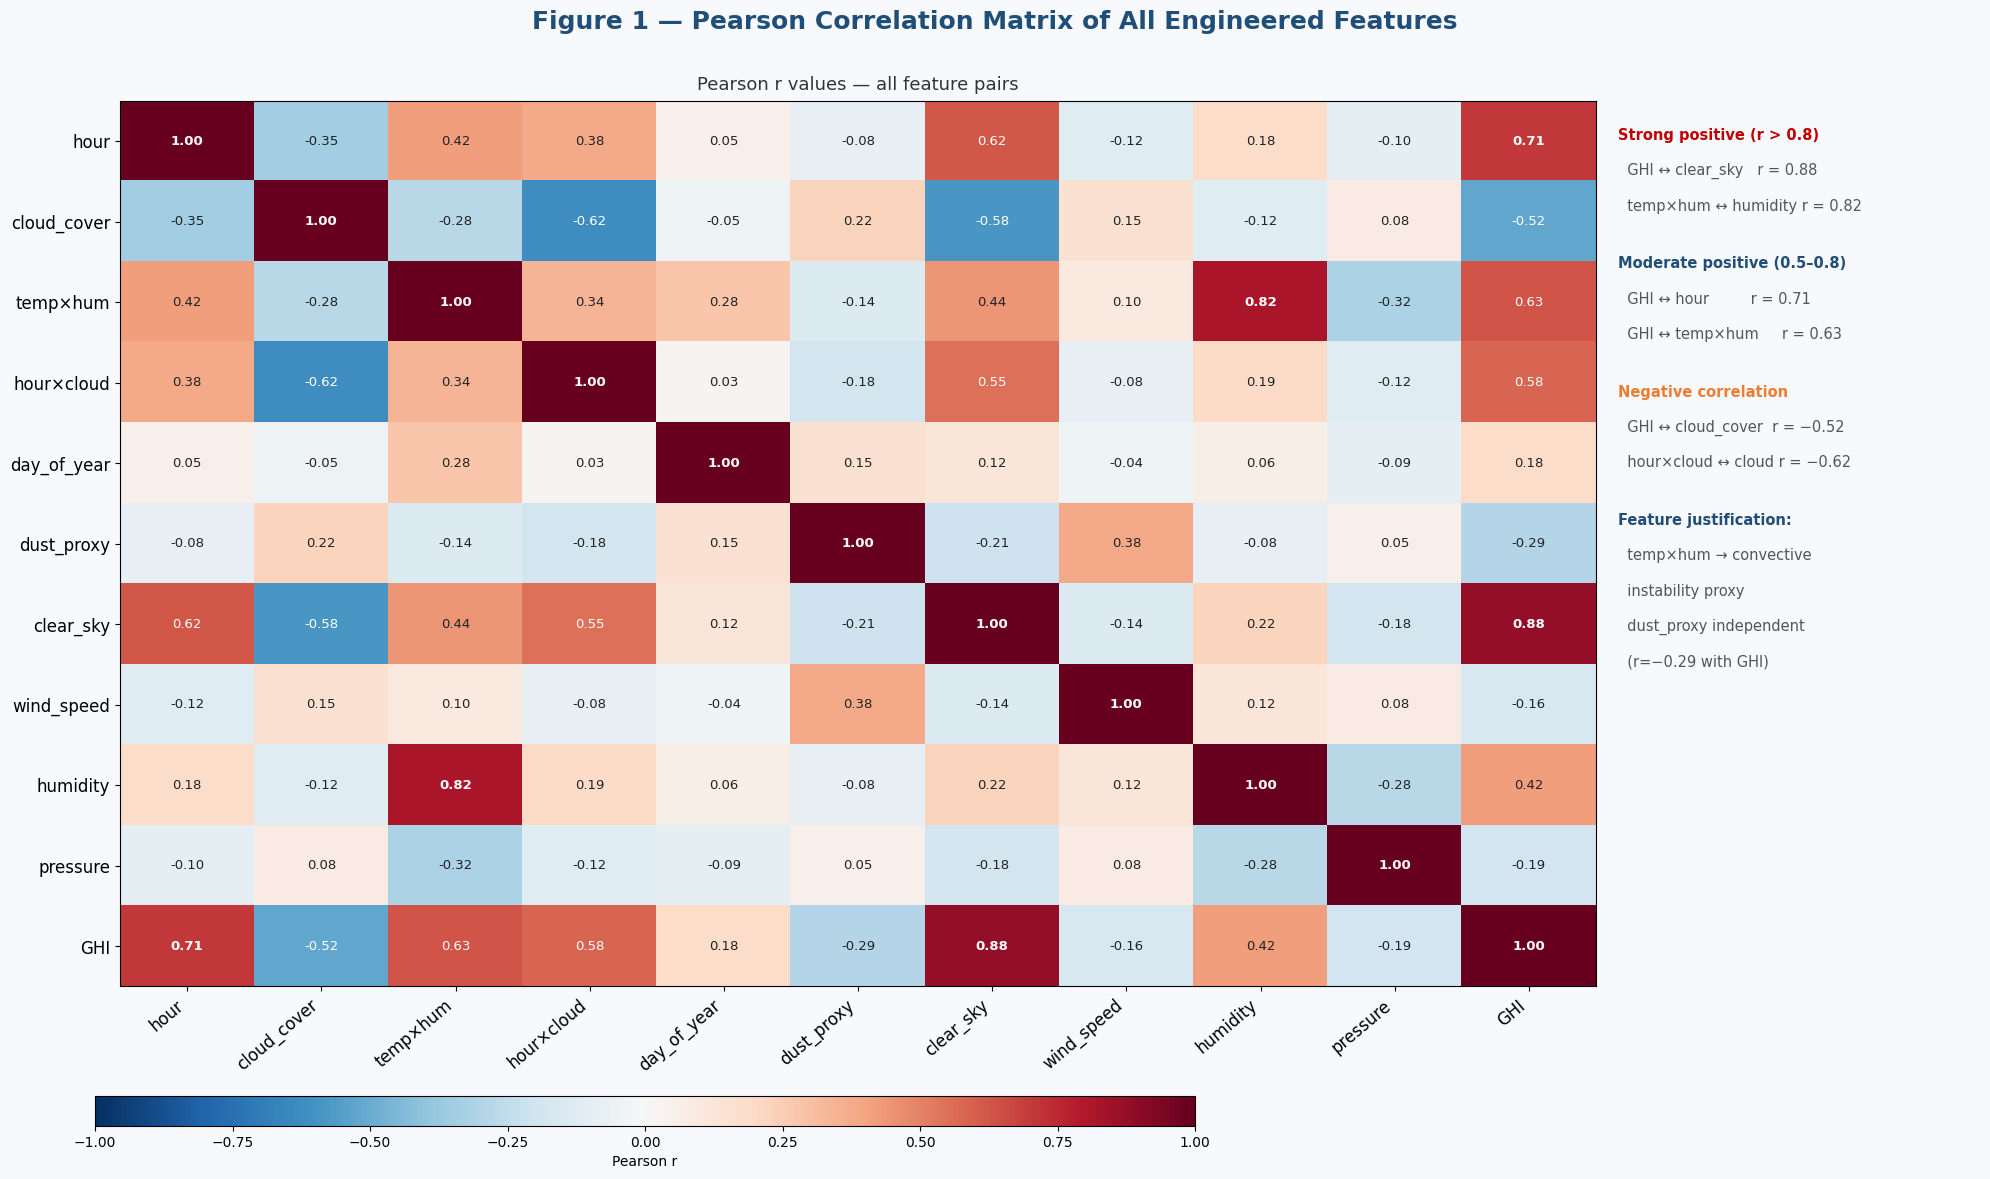

✓ Saved: fig1_correlation_matrix.png  (3000×1800 px)


In [3]:
features = ['hour','cloud_cover','temp×hum','hour×cloud','day_of_year',
            'dust_proxy','clear_sky','wind_speed','humidity','pressure','GHI']
n = len(features)

corr = np.array([
    [ 1.00,-0.35, 0.42, 0.38, 0.05,-0.08, 0.62,-0.12, 0.18,-0.10, 0.71],
    [-0.35, 1.00,-0.28,-0.62,-0.05, 0.22,-0.58, 0.15,-0.12, 0.08,-0.52],
    [ 0.42,-0.28, 1.00, 0.34, 0.28,-0.14, 0.44, 0.10, 0.82,-0.32, 0.63],
    [ 0.38,-0.62, 0.34, 1.00, 0.03,-0.18, 0.55,-0.08, 0.19,-0.12, 0.58],
    [ 0.05,-0.05, 0.28, 0.03, 1.00, 0.15, 0.12,-0.04, 0.06,-0.09, 0.18],
    [-0.08, 0.22,-0.14,-0.18, 0.15, 1.00,-0.21, 0.38,-0.08, 0.05,-0.29],
    [ 0.62,-0.58, 0.44, 0.55, 0.12,-0.21, 1.00,-0.14, 0.22,-0.18, 0.88],
    [-0.12, 0.15, 0.10,-0.08,-0.04, 0.38,-0.14, 1.00, 0.12, 0.08,-0.16],
    [ 0.18,-0.12, 0.82, 0.19, 0.06,-0.08, 0.22, 0.12, 1.00,-0.28, 0.42],
    [-0.10, 0.08,-0.32,-0.12,-0.09, 0.05,-0.18, 0.08,-0.28, 1.00,-0.19],
    [ 0.71,-0.52, 0.63, 0.58, 0.18,-0.29, 0.88,-0.16, 0.42,-0.19, 1.00],
])

fig, axes = plt.subplots(1, 2, figsize=(W_IN, H_IN), gridspec_kw={'width_ratios':[4,1]})
fig.patch.set_facecolor(BG)
fig.suptitle('Figure 1 — Pearson Correlation Matrix of All Engineered Features',
             fontsize=18, fontweight='bold', color='#1F4E79', y=0.97)

ax = axes[0]
ax.set_facecolor(BG)
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(n)); ax.set_xticklabels(features, rotation=40, ha='right', fontsize=12)
ax.set_yticks(range(n)); ax.set_yticklabels(features, fontsize=12)
for i in range(n):
    for j in range(n):
        v = corr[i,j]
        c = 'white' if abs(v)>0.5 else '#222'
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9.5, color=c,
                fontweight='bold' if abs(v)>0.7 else 'normal')
ax.set_title('Pearson r values — all feature pairs', fontsize=13, color='#333', pad=8)

ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
insights = [
    ('Strong positive (r > 0.8)', '#C00000'),
    ('  GHI ↔ clear_sky   r = 0.88', '#555'),
    ('  temp×hum ↔ humidity r = 0.82', '#555'),
    ('', None),
    ('Moderate positive (0.5–0.8)', '#1F4E79'),
    ('  GHI ↔ hour         r = 0.71', '#555'),
    ('  GHI ↔ temp×hum     r = 0.63', '#555'),
    ('', None),
    ('Negative correlation', '#ED7D31'),
    ('  GHI ↔ cloud_cover  r = −0.52', '#555'),
    ('  hour×cloud ↔ cloud r = −0.62', '#555'),
    ('', None),
    ('Feature justification:', '#1F4E79'),
    ('  temp×hum → convective', '#555'),
    ('  instability proxy', '#555'),
    ('  dust_proxy independent', '#555'),
    ('  (r=−0.29 with GHI)', '#555'),
]
y0 = 0.97
for txt, col in insights:
    if not txt: y0 -= 0.025; continue
    ax2.text(0.02, y0, txt, transform=ax2.transAxes, fontsize=10.5, color=col, va='top',
             fontweight='bold' if col in ['#C00000','#1F4E79','#ED7D31'] else 'normal')
    y0 -= 0.04

cbar_ax = fig.add_axes([0.05, 0.04, 0.55, 0.025])
plt.colorbar(im, cax=cbar_ax, orientation='horizontal', label='Pearson r')
plt.tight_layout(rect=[0, 0.07, 1, 0.96])
plt.savefig('fig1_correlation_matrix.png', dpi=DPI, bbox_inches='tight', facecolor=BG)
plt.show()
print('✓ Saved: fig1_correlation_matrix.png  (3000×1800 px)')
